# Part 2 – Ablation study of the Topology-Aware Attention U-Net (multi-task retinal vessel + A/V segmentation, CIMT classification and regression)

Companion of **`attention-u-net-Q1_part1_main.ipynb`** (training, test evaluation, comparisons, explainability, robustness, export). This notebook is **self-contained**: it rebuilds the same data split, scaler, model, losses and metrics (cells copied unchanged from Part 1) and then runs Section 25, the ablation with real re-training of seven variants (resumable, time-guarded). It does **not** need the trained checkpoint of Part 1. Run it in its own session with the same Kaggle datasets attached.

Figure / table numbers produced here start again at 1 (e.g. `Fig01_ablation_dotplots`); renumber them when you assemble the manuscript.

## 1. Setup


In [1]:
import os, re, glob, json, time, random, math, warnings, copy, zipfile, shutil, subprocess, sys
import numpy as np, pandas as pd
from PIL import Image
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, Patch
from matplotlib.lines import Line2D
import seaborn as sns
from IPython.display import display, HTML

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             accuracy_score, f1_score, precision_score, recall_score, matthews_corrcoef,
                             brier_score_loss, confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda | torch 2.11.0+cu130
GPU: Tesla T4


## 2. Config and switches


In [2]:
CFG = dict(
    images_dir = "/kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset",
    masks_dir  = "/kaggle/input/datasets/rofikbme/fundus-image/predicted_masks_5806",
    csv_path   = "/kaggle/input/datasets/rofikbme/fundus-image/data_info.csv",
    av_masks_dir = "/kaggle/input/datasets/amimulhasan/fundus-imagel/Fundus_A and V/Fundus_A and V",
    out_dir    = "/kaggle/working",
    img_size   = 512,
    batch_size = 8,
    epochs     = 30,
    lr         = 1e-4,
    weight_decay = 1e-5,
    num_workers = 2,
    base_ch    = 32,          # Attention U-Net base channels
    # loss weights
    lam        = 0.5,
    w_cl       = 0.5,
    w_wb       = 0.5,
    cl_iters   = 10,
    thin_boost = 2.0,
    branch_boost = 4.0,
    w_seg = 1.0, w_cls = 1.0, w_reg = 1.0, w_av = 1.0,
    amp        = True,
    seed       = 42,
    debug      = False,
)

RUN_TRAINING  = True
CKPT_DIR      = CFG["out_dir"]
GENDER_NAMES  = {0: "Gender 0", 1: "Gender 1"}
CLASS_NAMES   = {0: "Class 0", 1: "Class 1"}
AV_CLASS_NAMES = {0: "Background", 1: "Artery", 2: "Vein"}

os.makedirs(CFG["out_dir"], exist_ok=True)
set_seed(CFG["seed"])
USE_AMP = bool(CFG["amp"] and device.type == "cuda")
if CFG["debug"]:
    CFG.update(epochs=2, img_size=128, batch_size=4)

def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP)
print(CFG)


{'images_dir': '/kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset', 'masks_dir': '/kaggle/input/datasets/rofikbme/fundus-image/predicted_masks_5806', 'csv_path': '/kaggle/input/datasets/rofikbme/fundus-image/data_info.csv', 'av_masks_dir': '/kaggle/input/datasets/amimulhasan/fundus-imagel/Fundus_A and V/Fundus_A and V', 'out_dir': '/kaggle/working', 'img_size': 512, 'batch_size': 8, 'epochs': 30, 'lr': 0.0001, 'weight_decay': 1e-05, 'num_workers': 2, 'base_ch': 32, 'lam': 0.5, 'w_cl': 0.5, 'w_wb': 0.5, 'cl_iters': 10, 'thin_boost': 2.0, 'branch_boost': 4.0, 'w_seg': 1.0, 'w_cls': 1.0, 'w_reg': 1.0, 'w_av': 1.0, 'amp': True, 'seed': 42, 'debug': False}


## 3. Journal formatting helpers (Times New Roman 12 pt bold, 600 dpi)


In [3]:
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
FIG_DPI, SAVE_TIFF = 600, True
Image.MAX_IMAGE_PIXELS = None
FS = 12

sns.set_theme(style="ticks", context="notebook", palette="colorblind")
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif", "Nimbus Roman", "serif"],
    "font.size": FS, "font.weight": "bold",
    "axes.titlesize": FS, "axes.titleweight": "bold",
    "axes.labelsize": FS, "axes.labelweight": "bold",
    "xtick.labelsize": FS, "ytick.labelsize": FS,
    "legend.fontsize": FS, "legend.title_fontsize": FS, "legend.frameon": False,
    "figure.titlesize": FS, "figure.titleweight": "bold",
    "axes.linewidth": 1.5, "xtick.major.width": 1.5, "ytick.major.width": 1.5,
    "xtick.major.size": 5, "ytick.major.size": 5, "lines.linewidth": 2.0,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.05,
    "savefig.facecolor": "white", "figure.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "mathtext.fontset": "stix", "mathtext.default": "bf",
})
PAL = sns.color_palette("colorblind")

FIG_DIR = os.path.join(CFG["out_dir"], "journal_figures")
TAB_DIR = os.path.join(CFG["out_dir"], "journal_tables")
for _d in (FIG_DIR, TAB_DIR):
    os.makedirs(_d, exist_ok=True)
FIG_REGISTRY, TAB_REGISTRY = [], []

def _slot(registry, stem):
    for i, r in enumerate(registry):
        if r["stem"] == stem:
            return i + 1, i
    return len(registry) + 1, None

def say(text):
    display(HTML(f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:6px 0">{text}</p>'))

def ttl(ax, tag, text):
    ax.set_title(f"({tag}) {text}", loc="left", fontsize=FS, fontweight="bold", fontfamily="serif")

def save_fig(fig, stem, caption, dpi=None):
    n, old = _slot(FIG_REGISTRY, stem)
    dpi = dpi or FIG_DPI
    base = os.path.join(FIG_DIR, f"Fig{n:02d}_{stem}")
    fig.savefig(base + ".png", dpi=dpi)
    fig.savefig(base + ".pdf")
    tif = None
    if SAVE_TIFF:
        try:
            fig.savefig(base + ".tiff", dpi=dpi, pil_kwargs={"compression": "tiff_lzw"})
            tif = base + ".tiff"
        except Exception as e:
            print("  (TIFF export skipped:", type(e).__name__, e, ")")
    rec = dict(no=n, label=f"Fig. {n}", stem=stem, caption=caption,
               png=base + ".png", pdf=base + ".pdf", tiff=tif)
    if old is None:
        FIG_REGISTRY.append(rec)
    else:
        FIG_REGISTRY[old] = rec
    plt.show()
    display(HTML(
        f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:4px 0 18px 0">'
        f'Fig. {n}. {caption}</p>'))

def _table_css(align):
    return [
        {"selector": "", "props": [("border-collapse", "collapse"),
                                   ("border-top", "2px solid currentColor"),
                                   ("border-bottom", "2px solid currentColor"),
                                   ("margin", "4px 0 6px 0"),
                                   ("font-family", "Times New Roman, serif")]},
        {"selector": "th", "props": [("font-size", "12pt"), ("font-weight", "bold"),
                                     ("text-align", "center"),
                                     ("border-bottom", "1.5px solid currentColor"),
                                     ("padding", "5px 14px"),
                                     ("background-color", "transparent"),
                                     ("font-family", "Times New Roman, serif")]},
        {"selector": "td", "props": [("font-size", "12pt"), ("font-weight", "bold"),
                                     ("text-align", align), ("padding", "4px 14px"),
                                     ("border", "none"),
                                     ("font-family", "Times New Roman, serif")]},
    ]

def show_table(df, stem, caption, index=False, precision=4, note=None, align="center",
               best_max=(), best_min=()):
    n, old = _slot(TAB_REGISTRY, stem)
    base = os.path.join(TAB_DIR, f"Table{n:02d}_{stem}")
    df.to_csv(base + ".csv", index=index)
    try:
        df.to_latex(base + ".tex", index=index, escape=True,
                    caption=caption.replace("%", r"\%"), label=f"tab:{stem}",
                    float_format=lambda v: f"{v:.{precision}f}")
    except Exception as e:
        print("  (LaTeX export skipped:", type(e).__name__, ")")
    rec = dict(no=n, label=f"Table {n}", stem=stem, caption=caption, df=df.copy(),
               index=index, precision=precision, note=note,
               csv=base + ".csv", tex=base + ".tex")
    if old is None:
        TAB_REGISTRY.append(rec)
    else:
        TAB_REGISTRY[old] = rec
    display(HTML(
        f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:12px 0 2px 0">'
        f'Table {n}. {caption}</p>'))
    sty = df.style
    if not index:
        sty = sty.hide(axis="index")
    sty = sty.format(precision=precision, na_rep="–").set_table_styles(_table_css(align))
    if best_max:
        sty = sty.highlight_max(subset=list(best_max), props="text-decoration: underline;")
    if best_min:
        sty = sty.highlight_min(subset=list(best_min), props="text-decoration: underline;")
    display(sty)
    if note:
        display(HTML(
            f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:2px 0 14px 0">'
            f'{note}</p>'))

def fmt_ci(m, lo, hi, d=4):
    return f"{m:.{d}f} ({lo:.{d}f}–{hi:.{d}f})"

from contextlib import contextmanager
@contextmanager
def safe(name):
    try:
        yield
    except Exception as e:
        import traceback
        traceback.print_exc()
        print(f"\n[WARNING] section '{name}' failed and was skipped: {type(e).__name__}: {e}")

print("Journal style ready: Times New Roman | 12 pt bold | 600 dpi | figures ->", FIG_DIR)


Journal style ready: Times New Roman | 12 pt bold | 600 dpi | figures -> /kaggle/working/journal_figures


## 4. Data split and scaler (same code as Part 1, Section 4; Table 1 / Fig. 1 are produced in Part 1)

In [4]:

# ---- sanity-check the input paths early, with a readable message ----
for _k in ("images_dir", "masks_dir", "csv_path"):
    if not os.path.exists(CFG[_k]):
        raise FileNotFoundError(f"CFG['{_k}'] does not exist: {CFG[_k]}\nEdit the path in the Config cell.")
if not os.path.isdir(CFG["av_masks_dir"]):
    print("[WARNING] A/V mask folder not found -> Task 4 will be skipped (has_av = 0 for all images).")

def get_patient_id(base_name):
    return re.sub(r'(_L|_R|_OD|_OS)$', '', base_name, flags=re.IGNORECASE)

df = pd.read_csv(CFG["csv_path"])
print(df.shape)
display(df.head())

df["patient"] = df["image_name"].apply(lambda x: get_patient_id(os.path.splitext(str(x))[0]))
train_df = df[df["group"] == 1].reset_index(drop=True)
val_df   = df[df["group"] == 2].reset_index(drop=True)
test_df  = df[df["group"] == 3].reset_index(drop=True)

p_tr, p_va, p_te = set(train_df["patient"]), set(val_df["patient"]), set(test_df["patient"])
assert len(p_tr & p_va) == 0 and len(p_tr & p_te) == 0 and len(p_va & p_te) == 0
print(f"patients train/val/test = {len(p_tr)}/{len(p_va)}/{len(p_te)} | overlap tv=0 tt=0 vt=0")
print(f"images train/val/test = {len(train_df)} {len(val_df)} {len(test_df)}")

AGE_COL = "True_age" if "True_age" in df.columns else "age"
SCALER = dict(
    age_mu = float(train_df[AGE_COL].mean()),
    age_sd = float(train_df[AGE_COL].std() + 1e-8),
    t_mu   = float(train_df["thickness"].mean()),
    t_sd   = float(train_df["thickness"].std() + 1e-8),
)
print(SCALER)
print("label counts (train):", train_df["label"].value_counts().to_dict())


(5806, 7)


,image_name,thickness,label,True_age,age,gender,group
0,2491006_R.png,0.8,0,63,0.684932,0,1
1,2491006_L.png,0.8,0,63,0.684932,0,1
2,3730004_R.png,1.2,1,61,0.657534,1,1
3,3730004_L.png,1.2,1,61,0.657534,1,1
4,3730006_R.png,1.2,1,64,0.698630,1,1


patients train/val/test = 2603/200/100 | overlap tv=0 tt=0 vt=0
images train/val/test = 5206 400 200
{'age_mu': 48.09873223203996, 'age_sd': 12.819887685260232, 't_mu': 0.9951325393776411, 't_sd': 0.18354104606772081}
label counts (train): {1: 3808, 0: 1398}


## 5. Dataset and data loaders


In [5]:
def _find_file(folder, base, suffixes):
    """Return the first existing file folder/base+suffix (tries several extensions)."""
    for sfx in suffixes:
        p = os.path.join(folder, base + sfx)
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(f"No file for '{base}' in {folder} (tried {suffixes})")


def _load_av_mask(av_dir, base, size):
    if av_dir is None or not os.path.isdir(av_dir):
        return None
    candidates = [
        os.path.join(av_dir, base + "_av.png"),
        os.path.join(av_dir, base + "_AV.png"),
        os.path.join(av_dir, base + ".png"),
    ]
    for p in candidates:
        if os.path.isfile(p):
            m = np.asarray(Image.open(p).resize((size, size), Image.NEAREST))
            if m.ndim == 3:
                r, g, b = m[..., 0].astype(float), m[..., 1].astype(float), m[..., 2].astype(float)
                out = np.zeros(m.shape[:2], dtype=np.int64)
                out[(r > 120) & (r > g) & (r > b)] = 1
                out[(b > 120) & (b > r) & (b > g)] = 2
                return out
            m = m.astype(np.float32)
            if m.max() > 2:
                m = m / 255.0
            out = np.zeros_like(m, dtype=np.int64)
            out[m > 0.6] = 2
            out[(m > 0.2) & (m <= 0.6)] = 1
            return out
    art_p = [os.path.join(av_dir, base + "_artery.png"),
             os.path.join(av_dir, "artery", base + ".png"),
             os.path.join(av_dir, "Artery", base + ".png")]
    vein_p = [os.path.join(av_dir, base + "_vein.png"),
              os.path.join(av_dir, "vein", base + ".png"),
              os.path.join(av_dir, "Vein", base + ".png")]
    art = next((p for p in art_p if os.path.isfile(p)), None)
    vein = next((p for p in vein_p if os.path.isfile(p)), None)
    if art is None and vein is None:
        return None
    out = np.zeros((size, size), dtype=np.int64)
    if art is not None:
        a = np.asarray(Image.open(art).convert("L").resize((size, size), Image.NEAREST)) > 127
        out[a] = 1
    if vein is not None:
        v = np.asarray(Image.open(vein).convert("L").resize((size, size), Image.NEAREST)) > 127
        out[v] = 2
    return out


class MTDataset(Dataset):
    def __init__(self, images_dir, masks_dir, av_masks_dir, df, img_size=512, augment=False, scaler=None):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.av_masks_dir = av_masks_dir
        self.df = df.reset_index(drop=True)
        self.img_size = img_size
        self.augment = augment
        self.sc = scaler if scaler is not None else SCALER
        n_av = 0
        for i in range(min(80, len(self.df))):
            base = os.path.splitext(str(self.df.iloc[i]["image_name"]))[0]
            if _load_av_mask(av_masks_dir, base, 64) is not None:
                n_av += 1
        print(f"  A/V mask probe (first 80): {n_av}/80 found")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        base = os.path.splitext(str(row["image_name"]))[0]
        s = self.img_size
        img_path = _find_file(self.images_dir, base, (".png", ".jpg", ".jpeg", ".tif", ".tiff"))
        mask_path = _find_file(self.masks_dir, base, ("_mask.png", "_mask.jpg", ".png", ".jpg"))
        img = Image.open(img_path).convert("RGB").resize((s, s), Image.BILINEAR)
        mask = Image.open(mask_path).convert("L").resize((s, s), Image.NEAREST)
        av = _load_av_mask(self.av_masks_dir, base, s)

        if self.augment:
            if random.random() < 0.5:
                img = img.transpose(Image.FLIP_LEFT_RIGHT)
                mask = mask.transpose(Image.FLIP_LEFT_RIGHT)
                if av is not None:
                    av = np.ascontiguousarray(np.fliplr(av))
            if random.random() < 0.5:
                a = random.uniform(-15, 15)
                img = img.rotate(a, resample=Image.BILINEAR)
                mask = mask.rotate(a, resample=Image.NEAREST)
                if av is not None:
                    av = np.asarray(Image.fromarray(av.astype(np.uint8)).rotate(a, resample=Image.NEAREST))

        img_np = np.asarray(img, dtype=np.float32) / 255.0
        mask_np = (np.asarray(mask, dtype=np.float32) / 255.0 > 0.5).astype(np.float32)
        if av is None:
            av_np = np.zeros((s, s), dtype=np.int64)
            has_av = 0.0
        else:
            av_np = av.astype(np.int64)
            has_av = 1.0

        if self.augment and random.random() < 0.3:
            rng = np.random.default_rng()
            img_np = np.clip(img_np + rng.normal(0, 0.02, img_np.shape), 0, 1).astype(np.float32)

        age = (float(row[AGE_COL]) - self.sc["age_mu"]) / self.sc["age_sd"]
        clin = torch.tensor([age, float(row["gender"])], dtype=torch.float32)
        thick = (float(row["thickness"]) - self.sc["t_mu"]) / self.sc["t_sd"]
        return (
            torch.from_numpy(img_np).permute(2, 0, 1).contiguous(),
            torch.from_numpy(mask_np).unsqueeze(0),
            torch.from_numpy(av_np).long(),
            torch.tensor(has_av, dtype=torch.float32),
            clin,
            torch.tensor(float(row["label"]), dtype=torch.float32),
            torch.tensor(thick, dtype=torch.float32),
        )


def _seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)


def make_ds_loader(df, augment, shuffle):
    ds = MTDataset(CFG["images_dir"], CFG["masks_dir"], CFG["av_masks_dir"],
                   df, CFG["img_size"], augment, SCALER)
    g = torch.Generator()
    g.manual_seed(CFG["seed"])
    dl = DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle, drop_last=augment,
                    num_workers=CFG["num_workers"], pin_memory=(device.type == "cuda"),
                    worker_init_fn=_seed_worker, generator=g)
    return ds, dl

train_ds, train_loader = make_ds_loader(train_df, True, True)
val_ds,   val_loader   = make_ds_loader(val_df, False, False)
test_ds,  test_loader  = make_ds_loader(test_df, False, False)
print(f"train={len(train_ds)} val={len(val_ds)} test={len(test_ds)}")


  A/V mask probe (first 80): 80/80 found
  A/V mask probe (first 80): 80/80 found
  A/V mask probe (first 80): 80/80 found
train=5206 val=400 test=200


## 6. Model: Attention U-Net Multi-Task (exactly matching the provided diagram)


In [6]:
# ============================================================
# Attention Gate (exactly as in the diagram)
# ============================================================
class AttentionGate(nn.Module):
    """
    Attention Gate from Oktay et al.
    Gating signal (from decoder) + Input features (from encoder skip)
    → Wg, Wx → Add → ReLU → Psi → Sigmoid → Resampler → α
    Output = α ⊙ Input Features
    """
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        # g: gating signal from coarser scale (decoder)
        # x: skip connection features from encoder
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        if g1.shape[2:] != x1.shape[2:]:
            g1 = F.interpolate(g1, size=x1.shape[2:], mode="bilinear", align_corners=False)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        # Resampler is already handled by the sigmoid + broadcast multiply
        return x * psi, psi


# ============================================================
# Basic Conv Block (Conv + BN + ReLU) × 2
# ============================================================
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)


# ============================================================
# Clinical MLP (for multi-task)
# ============================================================
class ClinicalMLP(nn.Module):
    def __init__(self, in_dim=2, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.LeakyReLU(0.01, inplace=True),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.01, inplace=True))
    def forward(self, x):
        return self.net(x)


# ============================================================
# Attention U-Net Multi-Task
# ============================================================
class AttentionUNetMultiTask(nn.Module):
    def __init__(self, in_ch=3, base_ch=32, clinical_dim=2, clinical_hidden=32,
                 fc_dim=128, use_clinical=True, n_av_classes=3):
        super().__init__()
        self.use_clinical = use_clinical
        self.clinical_hidden = clinical_hidden
        self.n_av_classes = n_av_classes

        # Encoder channels: base, 2×, 4×, 8×, 16×
        c1, c2, c3, c4, c5 = base_ch, base_ch*2, base_ch*4, base_ch*8, base_ch*16

        # ---------- Encoder ----------
        self.enc1 = ConvBlock(in_ch, c1)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(c1, c2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = ConvBlock(c2, c3)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = ConvBlock(c3, c4)
        self.pool4 = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(c4, c5)

        # ---------- Attention Gates ----------
        # g = up-sampled decoder features (same channels as the skip), x = encoder skip features
        self.att4 = AttentionGate(F_g=c4, F_l=c4, F_int=c4//2)
        self.att3 = AttentionGate(F_g=c3, F_l=c3, F_int=c3//2)
        self.att2 = AttentionGate(F_g=c2, F_l=c2, F_int=c2//2)
        self.att1 = AttentionGate(F_g=c1, F_l=c1, F_int=c1//2)

        # ---------- Decoder ----------
        self.up4 = nn.ConvTranspose2d(c5, c4, kernel_size=2, stride=2)
        self.dec4 = ConvBlock(c4 + c4, c4)

        self.up3 = nn.ConvTranspose2d(c4, c3, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(c3 + c3, c3)

        self.up2 = nn.ConvTranspose2d(c3, c2, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(c2 + c2, c2)

        self.up1 = nn.ConvTranspose2d(c2, c1, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(c1 + c1, c1)

        # ---------- Segmentation Heads ----------
        self.seg_head = nn.Conv2d(c1, 1, kernel_size=1)
        self.av_head  = nn.Conv2d(c1, n_av_classes, kernel_size=1)

        # ---------- Clinical + Classification / Regression ----------
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.clinical_mlp = ClinicalMLP(clinical_dim, clinical_hidden)
        self.shared_fc = nn.Sequential(
            nn.Linear(c5 + clinical_hidden, fc_dim),
            nn.LeakyReLU(0.01, inplace=True),
            nn.Dropout(0.3)
        )
        self.cls_head = nn.Linear(fc_dim, 1)
        self.reg_head = nn.Linear(fc_dim, 1)

    def forward(self, x, clinical=None):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))
        b  = self.bottleneck(self.pool4(e4))

        # Decoder + Attention Gates (as in diagram)
        d4 = self.up4(b)
        e4_att, _ = self.att4(g=d4, x=e4)
        d4 = self.dec4(torch.cat([d4, e4_att], dim=1))

        d3 = self.up3(d4)
        e3_att, _ = self.att3(g=d3, x=e3)
        d3 = self.dec3(torch.cat([d3, e3_att], dim=1))

        d2 = self.up2(d3)
        e2_att, _ = self.att2(g=d2, x=e2)
        d2 = self.dec2(torch.cat([d2, e2_att], dim=1))

        d1 = self.up1(d2)
        e1_att, _ = self.att1(g=d1, x=e1)
        d1 = self.dec1(torch.cat([d1, e1_att], dim=1))

        # Heads
        seg = self.seg_head(d1)
        av  = self.av_head(d1)

        # Classification & Regression from bottleneck + clinical
        cls_logit = reg_pred = None
        if clinical is not None:
            pooled = self.gap(b).flatten(1)
            if self.use_clinical:
                cf = self.clinical_mlp(clinical)
            else:
                cf = pooled.new_zeros(pooled.shape[0], self.clinical_hidden)
            h = self.shared_fc(torch.cat([pooled, cf], dim=1))
            cls_logit = self.cls_head(h).squeeze(1)
            reg_pred  = self.reg_head(h).squeeze(1)

        return dict(seg=seg, av=av, deep=[seg], cls=cls_logit, reg=reg_pred, att={})


# Instantiate
model = AttentionUNetMultiTask(
    in_ch=3,
    base_ch=CFG["base_ch"],
    clinical_dim=2,
    clinical_hidden=32,
    fc_dim=128,
    use_clinical=True,
    n_av_classes=3
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {n_params:,}")

with torch.no_grad():
    model.eval()
    o = model(torch.randn(2, 3, min(CFG["img_size"], 128), min(CFG["img_size"], 128), device=device),
              torch.randn(2, 2, device=device))
print("seg:", tuple(o["seg"].shape), "| av:", tuple(o["av"].shape),
      "| cls:", tuple(o["cls"].shape), "| reg:", tuple(o["reg"].shape))


Total parameters: 7,923,042
seg: (2, 1, 128, 128) | av: (2, 3, 128, 128) | cls: (2,) | reg: (2,)


## 9. Losses (vessel topology + multi-class A/V + CIMT) and metrics

Vessel: Dice + soft-clDice + thin/branch-weighted BCE. A/V: CE + Dice (only on images with A/V labels). CIMT: weighted BCE (classification) + Smooth-L1 (regression).

In [7]:
# ============================================================
# Losses: vessel topology (soft-clDice, thin/branch-weighted BCE) + multi-class A/V + CIMT tasks
# ============================================================
def soft_erode(x):
    p1 = -F.max_pool2d(-x, (3, 1), (1, 1), (1, 0))
    p2 = -F.max_pool2d(-x, (1, 3), (1, 1), (0, 1))
    return torch.min(p1, p2)

def soft_dilate(x):
    return F.max_pool2d(x, (3, 3), (1, 1), (1, 1))

def soft_open(x):
    return soft_dilate(soft_erode(x))

def soft_skel(x, iters=10):
    """Differentiable skeleton (Shit et al., clDice)."""
    x1 = soft_open(x)
    skel = F.relu(x - x1)
    for _ in range(iters):
        x = soft_erode(x)
        x1 = soft_open(x)
        delta = F.relu(x - x1)
        skel = skel + F.relu(delta - skel * delta)
    return skel


class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__(); self.s = smooth
    def forward(self, logits, target):
        p = torch.sigmoid(logits).flatten(1); t = target.flatten(1)
        d = (2 * (p * t).sum(1) + self.s) / (p.sum(1) + t.sum(1) + self.s)
        return (1 - d).mean()


class SoftclDiceLoss(nn.Module):
    def __init__(self, iters=10, smooth=1.0):
        super().__init__(); self.iters, self.s = iters, smooth
    def forward(self, logits, target):
        p = torch.sigmoid(logits)
        sp, st = soft_skel(p, self.iters), soft_skel(target, self.iters)
        d = (1, 2, 3)
        tprec = ((sp * target).sum(d) + self.s) / (sp.sum(d) + self.s)
        tsens = ((st * p).sum(d) + self.s) / (st.sum(d) + self.s)
        cl = 2 * tprec * tsens / (tprec + tsens + 1e-8)
        return (1 - cl).mean()


class TopoWeightedBCE(nn.Module):
    """BCE with extra weight on thin vessels (mask minus its opening) and branch points."""
    def __init__(self, thin_boost=2.0, branch_boost=4.0, open_k=5, iters=10):
        super().__init__()
        self.tb, self.bb, self.k, self.iters = thin_boost, branch_boost, open_k, iters
        self.register_buffer("nb_kernel", torch.ones(1, 1, 3, 3))

    @torch.no_grad()
    def weight_map(self, t):
        k, pad = self.k, self.k // 2
        er = -F.max_pool2d(-t, k, 1, pad)
        op = F.max_pool2d(er, k, 1, pad)
        thin = F.relu(t - op)
        skel = (soft_skel(t, self.iters) > 0.5).float()
        nb = F.conv2d(skel, self.nb_kernel.to(t.dtype), padding=1)
        branch = F.max_pool2d(skel * (nb >= 4).float(), 5, 1, 2)
        return 1.0 + self.tb * thin + self.bb * branch

    def forward(self, logits, target):
        w = self.weight_map(target)
        l = F.binary_cross_entropy_with_logits(logits, target, reduction="none")
        return (w * l).sum() / w.sum()


class MultiClassDiceLoss(nn.Module):
    """Soft Dice over foreground classes (1..C-1); samples without A/V labels are masked out."""
    def __init__(self, n_classes=3, smooth=1.0):
        super().__init__(); self.n, self.s = n_classes, smooth
    def forward(self, logits, target, valid):
        p = F.softmax(logits, 1)
        oh = F.one_hot(target, self.n).permute(0, 3, 1, 2).float()
        d = (2, 3)
        dice = (2 * (p * oh).sum(d) + self.s) / (p.sum(d) + oh.sum(d) + self.s)   # (B, C)
        per = 1 - dice[:, 1:].mean(1)
        return (per * valid).sum() / valid.sum().clamp(min=1.0)


class MultiTaskLoss(nn.Module):
    def __init__(self, lam, w_seg, w_cls, w_reg, w_av, pos_weight=None, cl_iters=10,
                 thin_boost=2.0, branch_boost=4.0, w_cl=0.5, w_wb=0.5):
        super().__init__()
        self.lam, self.w_seg, self.w_cls, self.w_reg, self.w_av = lam, w_seg, w_cls, w_reg, w_av
        self.w_cl, self.w_wb = w_cl, w_wb
        self.dice = DiceLoss()
        self.cldice = SoftclDiceLoss(cl_iters)
        self.wbce = TopoWeightedBCE(thin_boost, branch_boost, iters=cl_iters)
        self.av_dice = MultiClassDiceLoss(3)
        self.register_buffer("pos_weight", pos_weight if pos_weight is not None else torch.ones(1))

    def forward(self, out, mask, av, has_av, y_cls, y_reg):
        seg_logit = out["seg"].float()
        l_dice = self.dice(seg_logit, mask)
        l_cl = self.cldice(seg_logit, mask)
        l_wb = self.wbce(seg_logit, mask)
        l_seg = l_dice + self.w_cl * l_cl + self.w_wb * l_wb

        av_logit = out["av"].float()
        if has_av.sum() > 0:
            ce = F.cross_entropy(av_logit, av, reduction="none").mean((1, 2))
            l_ce = (ce * has_av).sum() / has_av.sum()
            l_av = (1 - self.lam) * l_ce + self.lam * self.av_dice(av_logit, av, has_av)
        else:
            l_av = av_logit.sum() * 0.0

        l_cls = F.binary_cross_entropy_with_logits(out["cls"].float(), y_cls, pos_weight=self.pos_weight)
        l_reg = F.smooth_l1_loss(out["reg"].float(), y_reg)

        total = self.w_seg * l_seg + self.w_cls * l_cls + self.w_reg * l_reg + self.w_av * l_av
        parts = dict(total=total.item(), seg=l_seg.item(), dice=l_dice.item(), cldice=l_cl.item(),
                     wbce=l_wb.item(), av=l_av.item(), cls=l_cls.item(), reg=l_reg.item())
        return total, parts


pos = int((train_df["label"] == 1).sum())
neg = int((train_df["label"] == 0).sum())
pos_weight = torch.tensor([neg / max(pos, 1)], device=device, dtype=torch.float32)

criterion = MultiTaskLoss(
    CFG["lam"], CFG["w_seg"], CFG["w_cls"], CFG["w_reg"], CFG["w_av"],
    pos_weight=pos_weight, cl_iters=CFG["cl_iters"],
    thin_boost=CFG["thin_boost"], branch_boost=CFG["branch_boost"],
    w_cl=CFG["w_cl"], w_wb=CFG["w_wb"]).to(device)

# quick smoke test of the loss on one real batch
_b = next(iter(val_loader))
_img, _m, _av, _hav, _cl, _y, _t = [x.to(device) for x in _b]
with torch.no_grad():
    _o = model(_img, _cl)
    _, _p = criterion(_o, _m, _av, _hav, _y, _t)
print("loss smoke test:", {k: round(v, 4) for k, v in _p.items()})
del _b, _img, _m, _av, _hav, _cl, _y, _t, _o


loss smoke test: {'total': 3.4952, 'seg': 1.5301, 'dice': 0.8438, 'cldice': 0.7074, 'wbce': 0.665, 'av': 1.0468, 'cls': 0.2423, 'reg': 0.676}


In [8]:
# ============================================================
# Evaluation metrics (numpy): overlap, topology, thin vessels, branch points, A/V
# ============================================================
from scipy import ndimage as ndi
from skimage.morphology import skeletonize, disk

_S8 = np.ones((3, 3), dtype=int)

def _dice(a, b):
    s = a.sum() + b.sum()
    return 1.0 if s == 0 else 2.0 * (a & b).sum() / s

def seg_metrics_np(pred, gt):
    """pred, gt: boolean (H, W). Returns dict of overlap + topology metrics."""
    pred, gt = pred.astype(bool), gt.astype(bool)
    tp = (pred & gt).sum(); fp = (pred & ~gt).sum(); fn = (~pred & gt).sum(); tn = (~pred & ~gt).sum()
    m = dict(dice=_dice(pred, gt), iou=tp / max(tp + fp + fn, 1),
             sens=tp / max(tp + fn, 1), spec=tn / max(tn + fp, 1), prec=tp / max(tp + fp, 1))
    sp, sg = skeletonize(pred), skeletonize(gt)
    tprec = (sp & gt).sum() / max(sp.sum(), 1)
    tsens = (sg & pred).sum() / max(sg.sum(), 1)
    m["cldice"] = 2 * tprec * tsens / max(tprec + tsens, 1e-8)
    # thin vessels = GT minus its opening with a disk(2) (≈ width < 5 px)
    thin = gt & ~ndi.binary_opening(gt, structure=disk(2))
    m["thin_recall"] = (thin & ndi.binary_dilation(pred, structure=disk(1))).sum() / thin.sum() if thin.sum() > 0 else np.nan
    # branch points on the GT skeleton, hit if predicted skeleton lies within 3 px
    nb = ndi.convolve(sg.astype(int), _S8, mode="constant")
    bp = sg & (nb >= 4)
    if bp.sum() > 0 and sp.sum() > 0:
        dt = ndi.distance_transform_edt(~sp)
        m["branch_recall"] = float((dt[bp] <= 3).mean())
    else:
        m["branch_recall"] = np.nan
    # Betti-0 (connected components) absolute error
    m["betti0_err"] = abs(ndi.label(pred, _S8)[1] - ndi.label(gt, _S8)[1])
    return m

def av_metrics_np(pred, gt):
    """pred, gt: integer (H, W) in {0,1,2}."""
    a = _dice(pred == 1, gt == 1); v = _dice(pred == 2, gt == 2)
    return dict(av_artery=a, av_vein=v, av_mean=(a + v) / 2)


## Helpers, bootstrap index and time-budget stub

In [9]:
# ============================================================
# Helpers shared with Part 1 (copied unchanged from Part 1, Sections 10 and 11) + patient index for the bootstrap
# ============================================================
def make_grad_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)

def to_dev(batch):
    return [b.to(device, non_blocking=True) for b in batch]

def soft_cldice_score(prob, gt, iters=10, s=1.0):
    """Per-sample clDice from soft skeletons (fast, GPU) – used only for validation monitoring."""
    sp, st = soft_skel(prob, iters), soft_skel(gt, iters)
    d = (1, 2, 3)
    tprec = ((sp * gt).sum(d) + s) / (sp.sum(d) + s)
    tsens = ((st * prob).sum(d) + s) / (st.sum(d) + s)
    return 2 * tprec * tsens / (tprec + tsens + 1e-8)


@torch.no_grad()
def run_inference(model, loader, keep_maps=False):
    model.eval()
    out = dict(cls_prob=[], reg_z=[], seg=[], av=[], gt_mask=[], gt_av=[], has_av=[])
    for batch in loader:
        img, mask, av, has_av, clin = [b.to(device) for b in batch[:5]]
        with autocast_ctx():
            o = model(img, clin)
        out["cls_prob"].append(torch.sigmoid(o["cls"].float()).cpu())
        out["reg_z"].append(o["reg"].float().cpu())
        if keep_maps:
            out["seg"].append((torch.sigmoid(o["seg"].float()) * 255).round().byte().cpu())
            out["av"].append(o["av"].argmax(1).byte().cpu())
            out["gt_mask"].append(mask.byte().cpu()); out["gt_av"].append(av.byte().cpu()); out["has_av"].append(has_av.cpu())
    return {k: torch.cat(v).numpy() for k, v in out.items() if len(v)}

# patient-level bootstrap index over the test images (same construction as Part 1, Section 11)
_pc, _pu = pd.factorize(test_df["patient"])
pat_idx = [np.where(_pc == k)[0] for k in range(len(_pu))]

# Part 2 trains no main model: tell the time-budget code of Section 25 that no main-training time has to be reserved
history = pd.DataFrame({"time_s": [0.0]})


## 25. Ablation study (real re-training of every variant)

Each variant is **re-trained from scratch** with the same split, seed, optimiser, augmentation and model-selection rule, and evaluated on the same 200 test images. One component is removed at a time:

| Variant | Attention gates | Topology-aware loss | A/V task | CIMT tasks | Clinical inputs |
|---|:-:|:-:|:-:|:-:|:-:|
| **Full model (proposed)** | ✔ | ✔ | ✔ | ✔ | ✔ |
| w/o attention gates | ✘ | ✔ | ✔ | ✔ | ✔ |
| w/o topology-aware loss (Dice only) | ✔ | ✘ | ✔ | ✔ | ✔ |
| w/o A/V task | ✔ | ✔ | ✘ | ✔ | ✔ |
| w/o clinical inputs | ✔ | ✔ | ✔ | ✔ | ✘ |
| w/o CIMT tasks (segmentation + A/V) | ✔ | ✔ | ✔ | ✘ | – |
| Vessel segmentation only | ✔ | ✔ | ✘ | ✘ | – |

**Time budget (important).** To keep the whole notebook inside the 11-hour target, all ablation runs use a **reduced protocol** (input 256 × 256, at most 20 epochs, early stopping). The number of epochs is *computed automatically* from the measured training time of the main run and the remaining time budget (`TOTAL_BUDGET_H`), so the ablation cannot overrun. The full model is **re-trained under the same reduced protocol**, so every comparison inside this section is like-for-like; the 512 × 512 headline results stay in Tables 4–6.

Each finished variant is stored in `/kaggle/working/ablation/*.npz`; if the session stops, run the notebook again and finished variants are **skipped** (resume). Statistics: patient-level paired bootstrap against the full model (same resamples for all variants).

In [10]:
# ============================================================
# 25.0  Ablation configuration, variants, time budget
# ============================================================
RUN_ABLATION     = True
ABL_SIZE         = 256       # input size of ALL ablation runs (reduced protocol)
ABL_EPOCHS_MAX   = 20
ABL_MIN_EPOCHS   = 8
ABL_PATIENCE     = 8
ABL_BOOT         = 1000
TOTAL_BUDGET_H   = 11.0      # wall-clock target of the whole notebook
ABL_CAP_H        = 5.5       # never spend more than this on the ablation
ABL_RESUME       = True
ABL_DIR          = os.path.join(CFG["out_dir"], "ablation"); os.makedirs(ABL_DIR, exist_ok=True)

_base = dict(gates=True, clinical=True, w_cl=CFG["w_cl"], w_wb=CFG["w_wb"], w_cls=CFG["w_cls"], w_reg=CFG["w_reg"], w_av=CFG["w_av"])
VARIANTS = [   # ordered by importance: if time runs out, the last ones are skipped
    dict(_base, key="full",     name="Full model (proposed)"),
    dict(_base, key="no_ag",    name="w/o attention gates",                 gates=False),
    dict(_base, key="no_topo",  name="w/o topology-aware loss (Dice only)", w_cl=0.0, w_wb=0.0),
    dict(_base, key="no_av",    name="w/o A/V task",                        w_av=0.0),
    dict(_base, key="no_clin",  name="w/o clinical inputs",                 clinical=False),
    dict(_base, key="no_cimt",  name="w/o CIMT tasks (seg + A/V)",          w_cls=0.0, w_reg=0.0),
    dict(_base, key="seg_only", name="Vessel segmentation only",            w_cls=0.0, w_reg=0.0, w_av=0.0),
]
def _act(v):
    return dict(cls=v["w_cls"] > 0, reg=v["w_reg"] > 0, av=v["w_av"] > 0)

_hist = globals().get("history")
main_h = float(_hist["time_s"].sum()) / 3600 if (_hist is not None and len(_hist) and "time_s" in _hist) else 3.5
abl_budget_h = float(np.clip(TOTAL_BUDGET_H - main_h - 1.0, 0.5, ABL_CAP_H))
print(f"main training took {main_h:.2f} h -> ablation budget {abl_budget_h:.2f} h "
      f"(target total {TOTAL_BUDGET_H:.0f} h incl. ~1 h reserve for evaluation / figures)")
print("variants:", ", ".join(v["key"] for v in VARIANTS))

main training took 0.00 h -> ablation budget 5.50 h (target total 11 h incl. ~1 h reserve for evaluation / figures)
variants: full, no_ag, no_topo, no_av, no_clin, no_cimt, seg_only


In [11]:
# ============================================================
# 25.1  Ablation: model variants, loaders, time calibration  (reduced protocol)
# ============================================================
class IdentityGate(nn.Module):
    # replaces an attention gate by a plain skip connection (same call signature, returns (x, None))
    def forward(self, g, x):
        return x, None

def build_variant(v):
    m = AttentionUNetMultiTask(in_ch=3, base_ch=CFG["base_ch"], clinical_dim=2, clinical_hidden=32, fc_dim=128,
                               use_clinical=v["clinical"], n_av_classes=3).to(device)
    if not v["gates"]:
        for k in (1, 2, 3, 4):
            setattr(m, f"att{k}", IdentityGate())
    return m

def build_loss(v):
    return MultiTaskLoss(CFG["lam"], CFG["w_seg"], v["w_cls"], v["w_reg"], v["w_av"], pos_weight=pos_weight,
                         cl_iters=CFG["cl_iters"], thin_boost=CFG["thin_boost"], branch_boost=CFG["branch_boost"],
                         w_cl=v["w_cl"], w_wb=v["w_wb"]).to(device)

def _abl_loader(df, augment, shuffle):
    ds = MTDataset(CFG["images_dir"], CFG["masks_dir"], CFG["av_masks_dir"], df, ABL_SIZE, augment, SCALER)
    g = torch.Generator(); g.manual_seed(CFG["seed"])
    dl = DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle, drop_last=augment, num_workers=CFG["num_workers"],
                    pin_memory=(device.type == "cuda"), worker_init_fn=_seed_worker, generator=g)
    return ds, dl

ABL_EPOCHS = ABL_MIN_EPOCHS
if RUN_ABLATION:
    with safe("ablation_setup"):
        _, abl_train_loader = _abl_loader(train_df, True, True)
        _, abl_val_loader   = _abl_loader(val_df, False, False)
        _, abl_test_loader  = _abl_loader(test_df, False, False)

        # ---- measure the real speed of one training step at the reduced size (data loading included) ----
        def _sync():
            if device.type == "cuda":
                torch.cuda.synchronize()
        _m = build_variant(VARIANTS[0]); _crit = build_loss(VARIANTS[0]); _m.train()
        _opt = torch.optim.AdamW(_m.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"]); _sc = make_grad_scaler()
        _it = iter(abl_train_loader); _ts = []
        for _k in range(10):
            _sync(); _t0 = time.time()
            _b = to_dev(next(_it)); _opt.zero_grad(set_to_none=True)
            with autocast_ctx():
                _o = _m(_b[0], _b[4])
            _l, _ = _crit(_o, _b[1], _b[2], _b[3], _b[5], _b[6])
            _sc.scale(_l).backward(); _sc.unscale_(_opt); nn.utils.clip_grad_norm_(_m.parameters(), 5.0); _sc.step(_opt); _sc.update()
            _sync()
            if _k >= 3:
                _ts.append(time.time() - _t0)
        step_s = float(np.median(_ts))
        epoch_s = step_s * len(abl_train_loader) * (1 + 0.35 * len(abl_val_loader) / max(len(abl_train_loader), 1))
        del _m, _crit, _opt, _sc, _it, _b, _o, _l
        if device.type == "cuda":
            torch.cuda.empty_cache()

        n_todo = sum(not (ABL_RESUME and os.path.exists(os.path.join(ABL_DIR, f"{v['key']}_{ABL_SIZE}.npz"))) for v in VARIANTS)
        per_var_s = abl_budget_h * 3600 / max(n_todo, 1)
        ABL_EPOCHS = int(np.clip((per_var_s - 150) / (epoch_s * 1.15), ABL_MIN_EPOCHS, ABL_EPOCHS_MAX))
        est_h = n_todo * (ABL_EPOCHS * epoch_s * 1.15 + 150) / 3600
        print(f"measured: {step_s:.2f} s/step -> ~{epoch_s:.0f} s/epoch at {ABL_SIZE}x{ABL_SIZE}")
        print(f"plan: {n_todo} variants x {ABL_EPOCHS} epochs (max {ABL_EPOCHS_MAX}) -> estimated {est_h:.2f} h "
              f"(budget {abl_budget_h:.2f} h); expected notebook total ~ {main_h + est_h + 0.5:.1f} h")
        if est_h > abl_budget_h * 1.05:
            print("[WARNING] even the minimum epoch count exceeds the budget; the last variants will be skipped by the time guard.")

  A/V mask probe (first 80): 80/80 found
  A/V mask probe (first 80): 80/80 found
  A/V mask probe (first 80): 80/80 found
measured: 0.58 s/step -> ~387 s/epoch at 256x256
plan: 7 variants x 8 epochs (max 20) -> estimated 7.21 h (budget 5.50 h); expected notebook total ~ 7.7 h
[WARNING] even the minimum epoch count exceeds the budget; the last variants will be skipped by the time guard.


In [12]:
# ============================================================
# 25.2  Ablation: train + evaluate every variant (resumable, time-guarded)
# ============================================================
@torch.no_grad()
def abl_val(m, v):
    m.eval(); act_ = _act(v)
    dices, cld, avs, P, Y, R, T = [], [], [], [], [], [], []
    for batch in abl_val_loader:
        img, mask, av, has_av, clin, y, t = to_dev(batch)
        with autocast_ctx():
            o = m(img, clin)
        prob = torch.sigmoid(o["seg"].float()); pred = (prob > 0.5).float()
        inter = (pred * mask).sum((1, 2, 3)); den = pred.sum((1, 2, 3)) + mask.sum((1, 2, 3))
        dices.append(((2 * inter + 1) / (den + 1)).cpu()); cld.append(soft_cldice_score(prob, mask).cpu())
        ap = o["av"].argmax(1)
        a = [(2 * ((ap == c) & (av == c)).sum((1, 2)) + 1) / ((ap == c).sum((1, 2)) + (av == c).sum((1, 2)) + 1) for c in (1, 2)]
        avs.append(((a[0] + a[1]) / 2)[has_av > 0].cpu())
        P.append(torch.sigmoid(o["cls"].float()).cpu()); Y.append(y.cpu()); R.append(o["reg"].float().cpu()); T.append(t.cpu())
    P, Y, R, T = [torch.cat(x).numpy() for x in (P, Y, R, T)]
    avc = torch.cat(avs).numpy()
    res = dict(val_dice=float(torch.cat(dices).mean()), val_cldice=float(torch.cat(cld).mean()),
               val_av=float(avc.mean()) if len(avc) else float("nan"),
               val_auc=float(roc_auc_score(Y, P)) if len(np.unique(Y)) > 1 else 0.5,
               val_mae_mm=float(np.abs(R - T).mean() * SCALER["t_sd"]))
    comps = [res["val_dice"], res["val_cldice"]]                       # only the heads that are trained enter the selection score
    if act_["av"] and np.isfinite(res["val_av"]): comps.append(res["val_av"])
    if act_["cls"]: comps.append(res["val_auc"])
    if act_["reg"]: comps.append(max(0.0, 1 - res["val_mae_mm"] / SCALER["t_sd"]))
    res["score"] = float(np.mean(comps))
    return res

def train_variant(v, epochs, deadline):
    set_seed(CFG["seed"]); abl_train_loader.generator.manual_seed(CFG["seed"])
    m = build_variant(v); crit = build_loss(v)
    opt = torch.optim.AdamW(m.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=CFG["lr"] * 0.01)
    scaler = make_grad_scaler()
    hist, best, best_ep, bad, best_state, truncated, t_start = [], -1.0, 0, 0, None, False, time.time()
    for ep in range(1, epochs + 1):
        m.train(); agg, nb = 0.0, 0; t0 = time.time()
        for batch in abl_train_loader:
            img, mask, av, has_av, clin, y, t = to_dev(batch)
            opt.zero_grad(set_to_none=True)
            with autocast_ctx():
                o = m(img, clin)
            loss, parts = crit(o, mask, av, has_av, y, t)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(m.parameters(), 5.0)
            scaler.step(opt); scaler.update()
            agg += parts["total"]; nb += 1
        sched.step()
        r = abl_val(m, v); r.update(epoch=ep, train_loss=agg / max(nb, 1)); hist.append(r)
        improved = r["score"] > best
        if improved:
            best, best_ep, bad = r["score"], ep, 0
            best_state = {k: x.detach().cpu().clone() for k, x in m.state_dict().items()}
        else:
            bad += 1
        print(f"   ep {ep:02d}/{epochs} | loss {r['train_loss']:.3f} | val Dice {r['val_dice']:.3f} clDice {r['val_cldice']:.3f} "
              f"A/V {r['val_av']:.3f} AUC {r['val_auc']:.3f} MAE {r['val_mae_mm']:.3f} | score {r['score']:.4f}{' *' if improved else ''} | {time.time() - t0:.0f}s")
        if bad >= ABL_PATIENCE:
            print("   early stopping"); break
        if time.time() > deadline and ep < epochs:
            truncated = True; print("   [time guard] stopping this variant early"); break
    m.load_state_dict(best_state); m.eval()
    return m, hist, best_ep, truncated, time.time() - t_start

def test_variant(m, v):
    vi = run_inference(m, abl_val_loader)
    if v["w_cls"] > 0:
        fpr_, tpr_, thr_ = roc_curve(val_df["label"].values, vi["cls_prob"]); thr = float(thr_[np.argmax(tpr_ - fpr_)])
    else:
        thr = 0.5
    ti = run_inference(m, abl_test_loader, keep_maps=True)
    rows = []
    for i in range(len(ti["cls_prob"])):
        r = seg_metrics_np(ti["seg"][i, 0] > 127, ti["gt_mask"][i, 0] > 0)
        if ti["has_av"][i] > 0:
            r.update(av_metrics_np(ti["av"][i].astype(np.int64), ti["gt_av"][i].astype(np.int64)))
        else:
            r.update(av_mean=np.nan)
        rows.append(r)
    R = pd.DataFrame(rows)
    return dict(label=test_df["label"].values.astype(int), thickness=test_df["thickness"].values.astype(float),
                prob=ti["cls_prob"].astype(float), reg_mm=(ti["reg_z"] * SCALER["t_sd"] + SCALER["t_mu"]).astype(float),
                dice=R["dice"].values, iou=R["iou"].values, cldice=R["cldice"].values, thin_recall=R["thin_recall"].values,
                branch_recall=R["branch_recall"].values, av_mean=R["av_mean"].values, thr=np.array(thr))

if RUN_ABLATION and "abl_train_loader" in globals():
    t_abl0 = time.time(); deadline_global = t_abl0 + abl_budget_h * 3600
    for vi_, v in enumerate(VARIANTS):
        path = os.path.join(ABL_DIR, f"{v['key']}_{ABL_SIZE}.npz")
        if ABL_RESUME and os.path.exists(path):
            print(f"[{vi_ + 1}/{len(VARIANTS)}] {v['name']}: found {os.path.basename(path)} -> skipped (resume)"); continue
        remaining = deadline_global - time.time()
        left = sum(not os.path.exists(os.path.join(ABL_DIR, f"{w['key']}_{ABL_SIZE}.npz")) for w in VARIANTS[vi_:])
        if remaining < 900:
            print(f"[{vi_ + 1}/{len(VARIANTS)}] {v['name']}: SKIPPED (time budget used up)"); continue
        print(f"\n[{vi_ + 1}/{len(VARIANTS)}] {v['name']}  ({ABL_EPOCHS} epochs, {remaining / 60:.0f} min of budget left)")
        with safe(f"ablation_{v['key']}"):
            m, hist, best_ep, trunc, secs = train_variant(v, ABL_EPOCHS, time.time() + remaining / max(left, 1))
            out = test_variant(m, v)
            meta = dict(key=v["key"], name=v["name"], params_M=sum(p.numel() for p in m.parameters()) / 1e6, best_epoch=best_ep,
                        epochs_run=len(hist), epochs_planned=ABL_EPOCHS, minutes=secs / 60, truncated=bool(trunc), size=ABL_SIZE, hist=hist)
            np.savez(path, meta=np.array(json.dumps(meta)), **out)
            print(f"   saved {os.path.basename(path)} | best epoch {best_ep} | {secs / 60:.1f} min | test Dice {np.mean(out['dice']):.4f}")
            del m
            if device.type == "cuda":
                torch.cuda.empty_cache()
    print(f"\nablation finished in {(time.time() - t_abl0) / 3600:.2f} h")
else:
    print("ablation skipped (RUN_ABLATION = False or setup failed)")


[1/7] Full model (proposed)  (8 epochs, 330 min of budget left)
   ep 01/8 | loss 2.496 | val Dice 0.759 clDice 0.770 A/V 0.478 AUC 0.833 MAE 0.166 | score 0.5872 * | 604s
   ep 02/8 | loss 1.731 | val Dice 0.817 clDice 0.801 A/V 0.645 AUC 0.857 MAE 0.139 | score 0.6729 * | 109s
   ep 03/8 | loss 1.410 | val Dice 0.832 clDice 0.811 A/V 0.703 AUC 0.865 MAE 0.146 | score 0.6828 * | 108s
   ep 04/8 | loss 1.294 | val Dice 0.853 clDice 0.823 A/V 0.748 AUC 0.867 MAE 0.133 | score 0.7127 * | 109s
   ep 05/8 | loss 1.242 | val Dice 0.856 clDice 0.830 A/V 0.764 AUC 0.867 MAE 0.138 | score 0.7136 * | 108s
   ep 06/8 | loss 1.215 | val Dice 0.850 clDice 0.827 A/V 0.766 AUC 0.866 MAE 0.141 | score 0.7078 | 108s
   ep 07/8 | loss 1.199 | val Dice 0.857 clDice 0.833 A/V 0.777 AUC 0.868 MAE 0.138 | score 0.7164 * | 108s
   ep 08/8 | loss 1.194 | val Dice 0.854 clDice 0.830 A/V 0.775 AUC 0.869 MAE 0.140 | score 0.7131 | 108s
   saved full_256.npz | best epoch 7 | 22.7 min | test Dice 0.8570

[2/7] w

Variant,Attention gates,Topology loss,A/V task,CIMT tasks,Clinical input,Params (M),Epochs run,Best epoch,Time (min)
Full model (proposed),✔,✔,✔,✔,✔,7.92,8,7,22.73
w/o attention gates,✘,✔,✔,✔,✔,7.83,8,7,12.95
w/o topology-aware loss (Dice only),✔,✘,✔,✔,✔,7.92,8,7,14.38
w/o A/V task,✔,✔,✘,✔,✔,7.92,8,5,14.40
w/o clinical inputs,✔,✔,✔,✔,✘,7.92,8,8,14.41
w/o CIMT tasks (seg + A/V),✔,✔,✔,✘,–,7.92,8,5,14.46
Vessel segmentation only,✔,✔,✘,✘,–,7.92,8,8,14.41


Variant,AUC,Accuracy,MAE (mm),Dice,clDice,Thin-vessel recall,A/V Dice
Full model (proposed),0.9376 (0.8862–0.9793),0.8900 (0.8250–0.9450),0.1092 (0.0918–0.1266),0.8570 (0.8545–0.8593),0.8831 (0.8803–0.8857),0.9516 (0.9493–0.9538),0.7791 (0.7752–0.7831)
w/o attention gates,0.9374 (0.8872–0.9784),0.8900 (0.8250–0.9450),0.1081 (0.0908–0.1256),0.8531 (0.8506–0.8553),0.8803 (0.8775–0.8830),0.9490 (0.9468–0.9511),0.7739 (0.7698–0.7781)
w/o topology-aware loss (Dice only),0.9409 (0.8909–0.9808),0.9000 (0.8400–0.9550),0.1116 (0.0942–0.1293),0.8542 (0.8517–0.8565),0.8748 (0.8718–0.8776),0.9405 (0.9380–0.9430),0.7754 (0.7710–0.7798)
w/o A/V task,0.9401 (0.8922–0.9803),0.9000 (0.8400–0.9500),0.1089 (0.0920–0.1257),0.8590 (0.8565–0.8612),0.8817 (0.8787–0.8846),0.9503 (0.9478–0.9528),–
w/o clinical inputs,0.8651 (0.7934–0.9280),0.7900 (0.7200–0.8600),0.1259 (0.1071–0.1458),0.8485 (0.8460–0.8508),0.8742 (0.8712–0.8770),0.9442 (0.9418–0.9466),0.7526 (0.7479–0.7571)
w/o CIMT tasks (seg + A/V),–,–,–,0.8660 (0.8637–0.8682),0.8885 (0.8861–0.8910),0.9561 (0.9538–0.9582),0.8043 (0.8005–0.8082)
Vessel segmentation only,–,–,–,0.8694 (0.8673–0.8713),0.8904 (0.8881–0.8927),0.9631 (0.9611–0.9650),–


Variant,AUC,Accuracy,MAE (mm),Dice,clDice,Thin-vessel recall,A/V Dice
w/o attention gates,"-0.0002 (-0.0052, +0.0046)","+0.0000 (+0.0000, +0.0000)","-0.0010 (-0.0020, -0.0002)*","-0.0039 (-0.0043, -0.0035)*","-0.0027 (-0.0034, -0.0021)*","-0.0026 (-0.0031, -0.0021)*","-0.0052 (-0.0067, -0.0036)*"
w/o topology-aware loss (Dice only),"+0.0033 (-0.0023, +0.0099)","+0.0100 (-0.0100, +0.0350)","+0.0024 (+0.0010, +0.0039)*","-0.0028 (-0.0033, -0.0024)*","-0.0083 (-0.0091, -0.0076)*","-0.0110 (-0.0118, -0.0102)*","-0.0036 (-0.0052, -0.0022)*"
w/o A/V task,"+0.0025 (-0.0039, +0.0099)","+0.0100 (+0.0000, +0.0300)","-0.0002 (-0.0027, +0.0021)","+0.0020 (+0.0014, +0.0026)*","-0.0013 (-0.0021, -0.0005)*","-0.0013 (-0.0023, -0.0003)*",–
w/o clinical inputs,"-0.0725 (-0.1152, -0.0369)*","-0.1000 (-0.1601, -0.0400)*","+0.0167 (+0.0080, +0.0267)*","-0.0085 (-0.0090, -0.0081)*","-0.0089 (-0.0096, -0.0082)*","-0.0074 (-0.0081, -0.0067)*","-0.0265 (-0.0282, -0.0249)*"
w/o CIMT tasks (seg + A/V),–,–,–,"+0.0090 (+0.0085, +0.0095)*","+0.0054 (+0.0047, +0.0061)*","+0.0045 (+0.0038, +0.0051)*","+0.0253 (+0.0236, +0.0272)*"
Vessel segmentation only,–,–,–,"+0.0124 (+0.0116, +0.0132)*","+0.0073 (+0.0065, +0.0082)*","+0.0115 (+0.0107, +0.0124)*",–


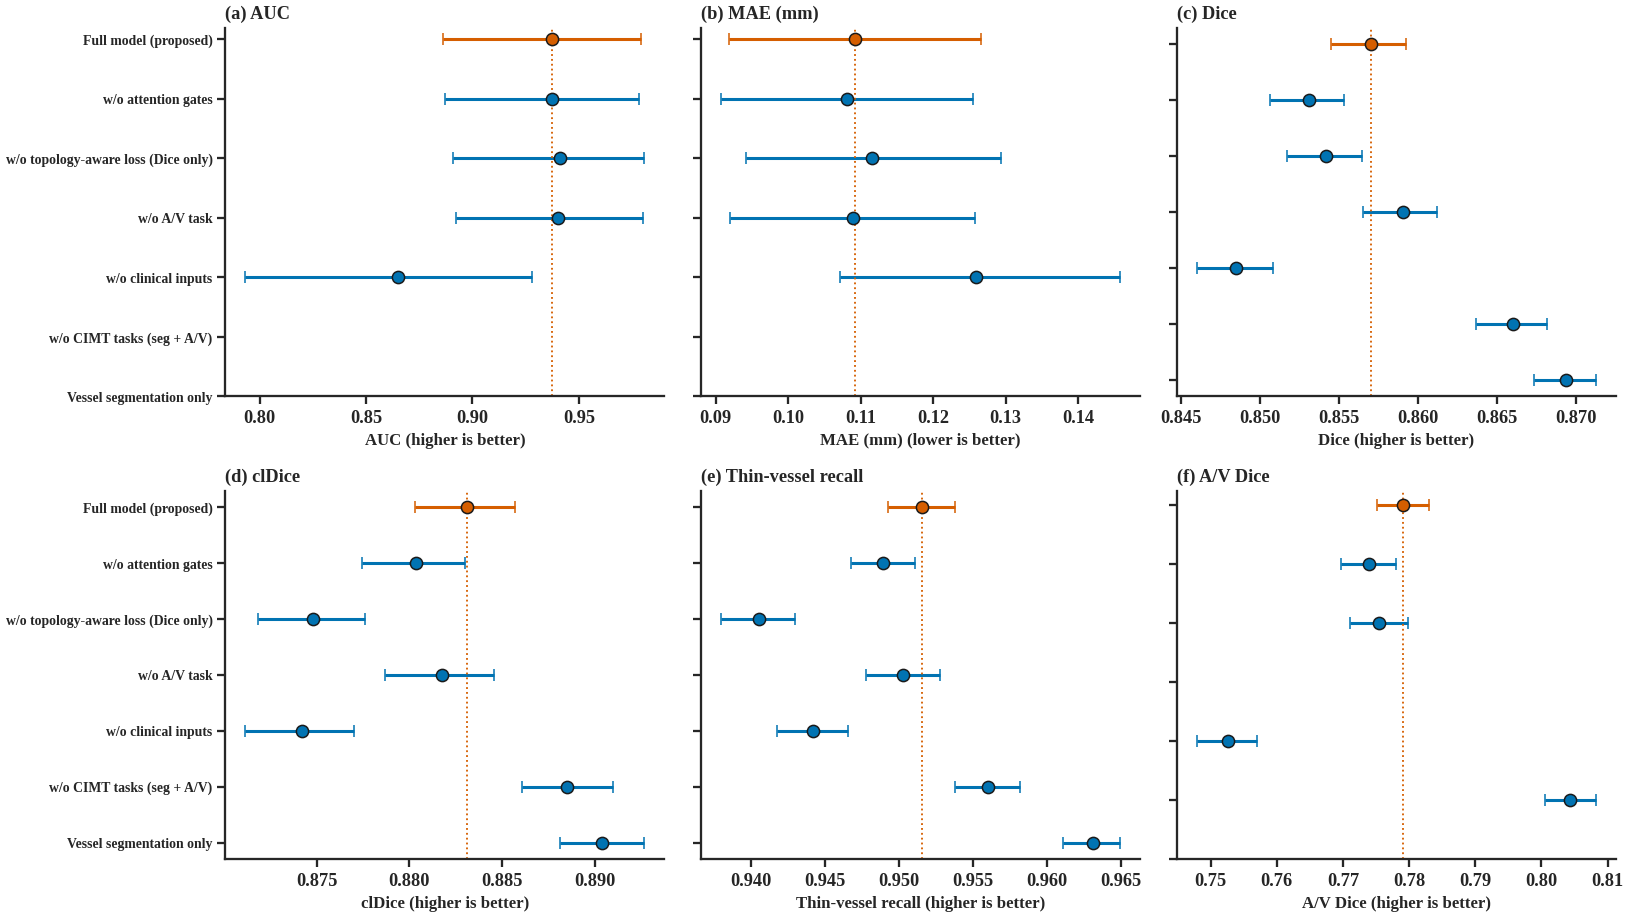

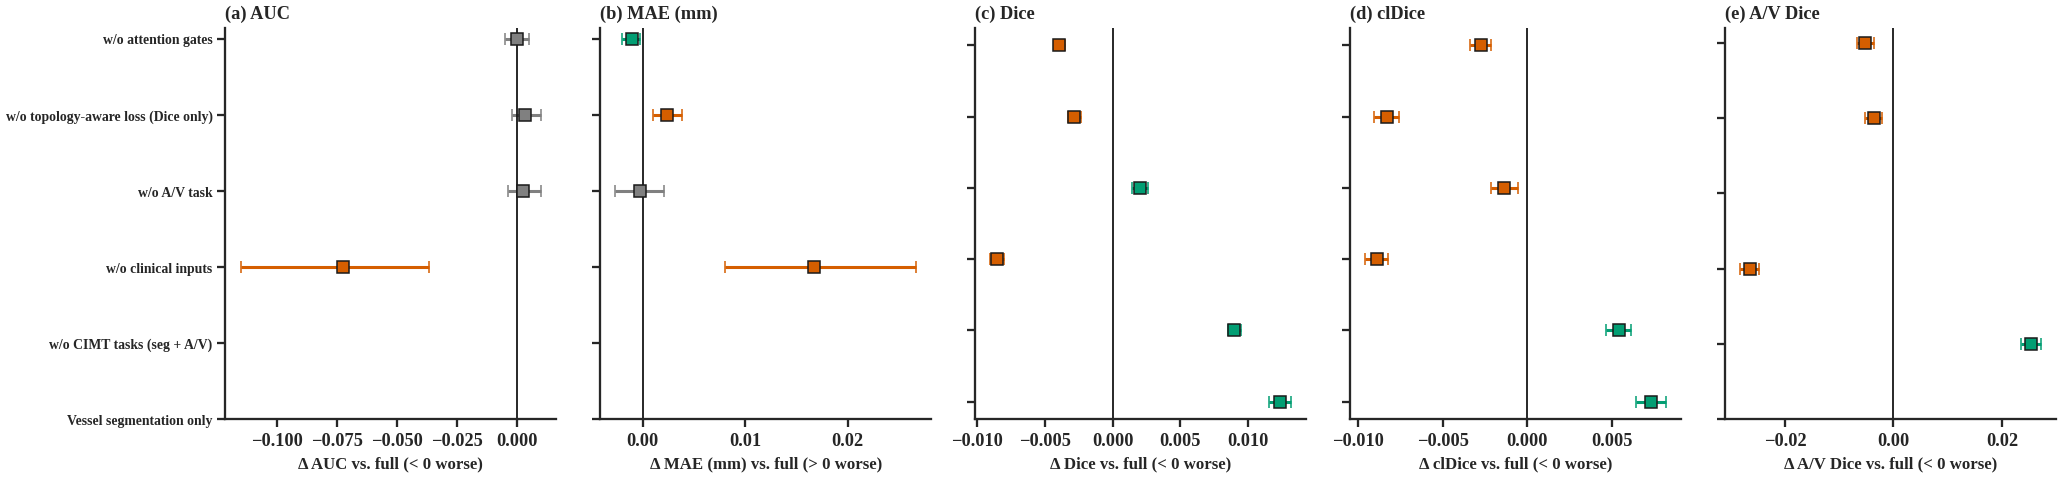

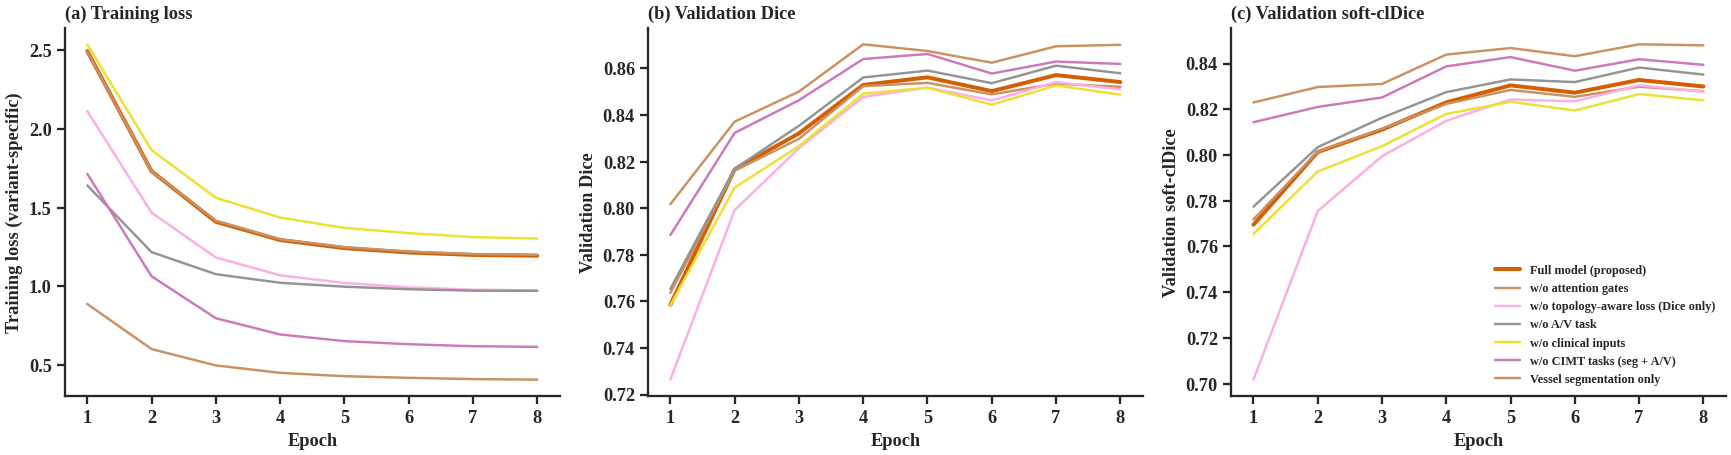

w/o attention gates: significantly worse on Dice (-0.0039), clDice (-0.0027), Thin-vessel recall (-0.0026), A/V Dice (-0.0052); significantly better on MAE (mm) (-0.0010).
w/o topology-aware loss (Dice only): significantly worse on MAE (mm) (+0.0024), Dice (-0.0028), clDice (-0.0083), Thin-vessel recall (-0.0110), A/V Dice (-0.0036).
w/o A/V task: significantly worse on clDice (-0.0013), Thin-vessel recall (-0.0013); significantly better on Dice (+0.0020).
w/o clinical inputs: significantly worse on AUC (-0.0725), Accuracy (-0.1000), MAE (mm) (+0.0167), Dice (-0.0085), clDice (-0.0089), Thin-vessel recall (-0.0074), A/V Dice (-0.0265).
w/o CIMT tasks (seg + A/V): no metric significantly worse than the full model; significantly better on Dice (+0.0090), clDice (+0.0054), Thin-vessel recall (+0.0045), A/V Dice (+0.0253).
Vessel segmentation only: no metric significantly worse than the full model; significantly better on Dice (+0.0124), clDice (+0.0073), Thin-vessel recall (+0.0115).


In [13]:
# ============================================================
# 25.3  Ablation results: Table + paired bootstrap against the full model + figures
# ============================================================
with safe("ablation_results"):
    LOAD = {}
    for v in VARIANTS:
        p_ = os.path.join(ABL_DIR, f"{v['key']}_{ABL_SIZE}.npz")
        if os.path.exists(p_):
            z = np.load(p_, allow_pickle=False); LOAD[v["key"]] = ({k: z[k] for k in z.files if k != "meta"}, json.loads(str(z["meta"])))
    miss = [v["name"] for v in VARIANTS if v["key"] not in LOAD]
    if miss:
        print("[note] variants not available (skipped by the time guard or failed):", ", ".join(miss))
    assert "full" in LOAD, "the full-model reference run is missing -> cannot build the ablation table"
    VS = [v for v in VARIANTS if v["key"] in LOAD]

    def _vm(d, idx, v):
        a = _act(v); y = d["label"][idx]; p = d["prob"][idx]
        o = {"Dice": float(np.mean(d["dice"][idx])), "clDice": float(np.mean(d["cldice"][idx])),
             "Thin-vessel recall": float(np.nanmean(d["thin_recall"][idx])),
             "A/V Dice": float(np.nanmean(d["av_mean"][idx])) if a["av"] and np.isfinite(d["av_mean"][idx]).any() else np.nan}
        thr = float(d["thr"])
        o["AUC"] = float(roc_auc_score(y, p)) if a["cls"] and len(np.unique(y)) > 1 else np.nan
        o["Accuracy"] = float(np.mean((p >= thr).astype(int) == y)) if a["cls"] else np.nan
        o["MAE (mm)"] = float(np.mean(np.abs(d["reg_mm"][idx] - d["thickness"][idx]))) if a["reg"] else np.nan
        return o

    rng_ = np.random.default_rng(CFG["seed"])
    DR = [np.concatenate([pat_idx[k] for k in rng_.integers(0, len(pat_idx), len(pat_idx))]) for _ in range(ABL_BOOT)]
    ALL = np.arange(len(LOAD["full"][0]["label"]))
    PT, BS = {}, {}
    for v in VS:
        d = LOAD[v["key"]][0]
        PT[v["key"]] = _vm(d, ALL, v)
        BS[v["key"]] = pd.DataFrame([_vm(d, ix, v) for ix in DR])
    METS = ["AUC", "Accuracy", "MAE (mm)", "Dice", "clDice", "Thin-vessel recall", "A/V Dice"]
    LOWER = {"MAE (mm)"}

    # ---- protocol table ----
    ck = lambda b: "✔" if b else "✘"
    proto = pd.DataFrame([{"Variant": v["name"], "Attention gates": ck(v["gates"]), "Topology loss": ck(v["w_cl"] > 0 or v["w_wb"] > 0),
                           "A/V task": ck(v["w_av"] > 0), "CIMT tasks": ck(v["w_cls"] > 0 or v["w_reg"] > 0),
                           "Clinical input": ck(v["clinical"]) if (v["w_cls"] > 0 or v["w_reg"] > 0) else "–",
                           "Params (M)": LOAD[v["key"]][1]["params_M"], "Epochs run": LOAD[v["key"]][1]["epochs_run"],
                           "Best epoch": LOAD[v["key"]][1]["best_epoch"], "Time (min)": LOAD[v["key"]][1]["minutes"]} for v in VS])
    show_table(proto, "ablation_protocol", "Ablation variants and training protocol (all runs: same split, seed, optimiser; reduced protocol).",
               precision=2, align="center",
               note=f"Reduced protocol: {ABL_SIZE}×{ABL_SIZE} input, ≤ {ABL_EPOCHS_MAX} epochs with early stopping (planned epochs = {ABL_EPOCHS}). "
                    "The full model was re-trained under the same protocol; the 512×512 headline results are in Tables 4–6.")

    # ---- main ablation table with 95 % CI ----
    def _ci(k, m_):
        s = BS[k][m_].dropna()
        return "–" if np.isnan(PT[k][m_]) or len(s) == 0 else fmt_ci(PT[k][m_], np.percentile(s, 2.5), np.percentile(s, 97.5), 4)
    tab_ab = pd.DataFrame([{"Variant": v["name"], **{m_: _ci(v["key"], m_) for m_ in METS}} for v in VS])
    show_table(tab_ab, "ablation_study", "Ablation study of the proposed multi-task Attention U-Net (test set, 95% patient-level bootstrap CI).",
               align="center",
               note="– = task not trained in that variant. Same reduced protocol for all rows. Classification threshold: Youden index on validation of each variant.")

    # ---- paired differences against the full model ----
    rows_ = []
    for v in VS[1:]:
        r = {"Variant": v["name"]}
        for m_ in METS:
            a, b = BS[v["key"]][m_], BS["full"][m_]
            if np.isnan(PT[v["key"]][m_]) or np.isnan(PT["full"][m_]):
                r[m_] = "–"; continue
            dlt = (a - b).dropna().values; pt_ = PT[v["key"]][m_] - PT["full"][m_]
            lo, hi = np.percentile(dlt, [2.5, 97.5]); pv = min(1.0, 2 * min(np.mean(dlt <= 0), np.mean(dlt >= 0)))
            star = "*" if (lo > 0 or hi < 0) else ""
            r[m_] = f"{pt_:+.4f} ({lo:+.4f}, {hi:+.4f}){star}"
        rows_.append(r)
    tab_d = pd.DataFrame(rows_)
    show_table(tab_d, "ablation_delta", "Change of each ablated variant relative to the full model (paired patient-level bootstrap).",
               align="center",
               note="Δ = variant − full model with 95% paired-bootstrap CI; * = CI excludes 0. For MAE a positive Δ means worse; for all other metrics a negative Δ means worse.")

    # ---- Fig. A: dot plot with CI per metric ----
    mets_plot = [m_ for m_ in ["AUC", "MAE (mm)", "Dice", "clDice", "Thin-vessel recall", "A/V Dice"]]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8.6))
    for k_, (ax, m_) in enumerate(zip(axes.ravel(), mets_plot)):
        ys = 0
        for j, v in enumerate(VS):
            val = PT[v["key"]][m_]
            if np.isnan(val): continue
            s = BS[v["key"]][m_].dropna(); lo, hi = np.percentile(s, 2.5), np.percentile(s, 97.5)
            c = PAL[3] if v["key"] == "full" else PAL[0]
            ax.errorbar(val, len(VS) - 1 - j, xerr=[[val - lo], [hi - val]], fmt="o", color=c, ecolor=c, capsize=4, ms=8, markeredgecolor="k")
        ax.set_yticks(range(len(VS))); ax.set_yticklabels([v["name"] for v in VS][::-1], fontsize=FS - 3)
        ax.axvline(PT["full"][m_], color=PAL[3], ls=":", lw=1.2)
        ax.set_xlabel(m_ + (" (lower is better)" if m_ in LOWER else " (higher is better)"), fontsize=FS - 1); ttl(ax, "abcdef"[k_], m_)
        if k_ % 3: ax.set_yticklabels([])
    plt.tight_layout()
    save_fig(fig, "ablation_dotplots",
             "Ablation study. Test performance (dots) with 95% patient-level bootstrap CI of the full model (orange) and of each variant with one "
             "component removed (blue). Dotted line = full model. Variants that do not train a task have no point for that task.")

    # ---- Fig. B: paired differences ----
    fig, axes = plt.subplots(1, 5, figsize=(19, 4.6))
    for ax, m_ in zip(axes, ["AUC", "MAE (mm)", "Dice", "clDice", "A/V Dice"]):
        for j, v in enumerate(VS[1:]):
            if np.isnan(PT[v["key"]][m_]) or np.isnan(PT["full"][m_]): continue
            dlt = (BS[v["key"]][m_] - BS["full"][m_]).dropna().values; pt_ = PT[v["key"]][m_] - PT["full"][m_]
            lo, hi = np.percentile(dlt, [2.5, 97.5]); sig = lo > 0 or hi < 0
            worse = (pt_ > 0) if m_ in LOWER else (pt_ < 0)
            c = PAL[3] if (sig and worse) else (PAL[2] if sig else "0.5")
            ax.errorbar(pt_, len(VS) - 2 - j, xerr=[[pt_ - lo], [hi - pt_]], fmt="s", color=c, ecolor=c, capsize=4, ms=8, markeredgecolor="k")
        ax.axvline(0, color="k", lw=1.2); ax.set_yticks(range(len(VS) - 1)); ax.set_yticklabels([v["name"] for v in VS[1:]][::-1], fontsize=FS - 3)
        ax.set_xlabel(f"Δ {m_} vs. full" + (" (> 0 worse)" if m_ in LOWER else " (< 0 worse)"), fontsize=FS - 1); ttl(ax, "abcde"[["AUC", "MAE (mm)", "Dice", "clDice", "A/V Dice"].index(m_)], m_)
        if ax is not axes[0]: ax.set_yticklabels([])
    plt.tight_layout()
    save_fig(fig, "ablation_paired_delta",
             "Paired change of each ablated variant relative to the full model with 95% paired bootstrap CI. Orange = significantly worse, "
             "green = significantly better, grey = CI includes zero.")

    # ---- Fig. C: validation curves ----
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    for j, v in enumerate(VS):
        h = pd.DataFrame(LOAD[v["key"]][1]["hist"]); kw = dict(color=PAL[3] if v["key"] == "full" else sns.color_palette("colorblind")[(j % 5) + 4 if j else 3],
                                                              lw=2.6 if v["key"] == "full" else 1.6, label=v["name"])
        axes[0].plot(h["epoch"], h["train_loss"], **kw); axes[1].plot(h["epoch"], h["val_dice"], **kw); axes[2].plot(h["epoch"], h["val_cldice"], **kw)
    for ax, (yl, tg) in zip(axes, [("Training loss (variant-specific)", "a"), ("Validation Dice", "b"), ("Validation soft-clDice", "c")]):
        ax.set_xlabel("Epoch"); ax.set_ylabel(yl); ttl(ax, tg, yl.split(" (")[0])
    axes[2].legend(fontsize=FS - 4, loc="lower right")
    plt.tight_layout()
    save_fig(fig, "ablation_training_curves",
             "Training behaviour of the ablation variants (reduced protocol). (a) training loss (each variant optimises its own loss, so absolute "
             "values are not comparable), (b) validation Dice, (c) validation soft-clDice.")

    # ---- auto-generated, hedged results text (check every sentence against the tables before use) ----
    lines = []
    for v in VS[1:]:
        worse, better = [], []
        for m_ in METS:
            if np.isnan(PT[v["key"]][m_]) or np.isnan(PT["full"][m_]): continue
            dlt = (BS[v["key"]][m_] - BS["full"][m_]).dropna().values; pt_ = PT[v["key"]][m_] - PT["full"][m_]
            lo, hi = np.percentile(dlt, [2.5, 97.5])
            if lo > 0 or hi < 0:
                is_worse = (pt_ > 0) if m_ in LOWER else (pt_ < 0)
                (worse if is_worse else better).append(f"{m_} ({pt_:+.4f})")
        txt = f"{v['name']}: "
        txt += ("significantly worse on " + ", ".join(worse)) if worse else "no metric significantly worse than the full model"
        if better: txt += "; significantly better on " + ", ".join(better)
        lines.append(txt + ".")
    with open(os.path.join(CFG["out_dir"], "ablation_results_text.md"), "w", encoding="utf-8") as f:
        f.write("# Ablation – auto-generated summary (95% paired bootstrap CI excludes 0)\n\n" + "\n\n".join(lines) + "\n")
    print("\n".join(lines))
    say("Check these sentences against Table 'Change of each ablated variant' before using them in the manuscript; "
        "variants that do not train a task cannot be compared on that task.")

## Export

In [14]:
# ============================================================
# Export of the ablation figures / tables
# ============================================================
with safe("ablation_export"):
    cap_path = os.path.join(CFG["out_dir"], "journal_captions_ablation.md")
    with open(cap_path, "w", encoding="utf-8") as f:
        f.write("# Figure captions\n\n")
        for r in FIG_REGISTRY:
            f.write(f"**{r['label']}.** {r['caption']}\n\n")
        f.write("# Table captions\n\n")
        for r in TAB_REGISTRY:
            f.write(f"**{r['label']}.** {r['caption']}" + (f" *{r['note']}*" if r.get("note") else "") + "\n\n")
    zip_abl = os.path.join(CFG["out_dir"], "journal_package_ablation.zip")
    with zipfile.ZipFile(zip_abl, "w", zipfile.ZIP_DEFLATED) as z:
        for d_ in (FIG_DIR, TAB_DIR):
            for fn in sorted(os.listdir(d_)):
                z.write(os.path.join(d_, fn), os.path.join(os.path.basename(d_), fn))
        for fn in ("ablation_results_text.md", "journal_captions_ablation.md"):
            fp = os.path.join(CFG["out_dir"], fn)
            if os.path.exists(fp):
                z.write(fp, fn)
    print("Package:", zip_abl, f"({os.path.getsize(zip_abl) / 1e6:.1f} MB)")
    print("Figures:", [r["stem"] for r in FIG_REGISTRY]); print("Tables:", [r["stem"] for r in TAB_REGISTRY])


Package: /kaggle/working/journal_package_ablation.zip (5.0 MB)
Figures: ['ablation_dotplots', 'ablation_paired_delta', 'ablation_training_curves']
Tables: ['ablation_protocol', 'ablation_study', 'ablation_delta']
